In [1]:
import os
GPU_ID = os.environ.get("GPU_ID", "1")
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
# --------------------------------------------------------------------------------------------------

import sys, json, time, math, copy, random, platform, warnings
from dataclasses import dataclass
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from sklearn.metrics import roc_auc_score, precision_recall_curve
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore", category=UserWarning, module="torchvision")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
if DEVICE.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU (nvidia-smi index {GPU_ID}): {p.name} | compute capability {p.major}.{p.minor} "
          f"| {p.total_memory / 2**30:.1f} GiB | visible devices: {torch.cuda.device_count()}")
    print(f"CUDA (torch build) {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()}")
    sm = f"sm_{p.major}{p.minor}"
    if sm not in torch.cuda.get_arch_list():
        print(f"WARNING: this PyTorch build has no native kernels for {sm}: {torch.cuda.get_arch_list()}")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: no CUDA GPU visible. Everything runs on CPU (slow) and TensorRT steps are skipped.")

try:
    import onnx
    print("onnx", onnx.__version__)
except ImportError:
    onnx = None
    print("onnx not installed -> Step 6 will be skipped")

try:
    import onnxruntime as ort
    if hasattr(ort, "preload_dlls"):
        try:
            ort.preload_dlls()          # load CUDA/cuDNN from the pip wheels PyTorch already installed
        except Exception as e:
            print("ort.preload_dlls() failed:", e)
    ORT_PROVIDERS = ort.get_available_providers()
    print("onnxruntime", ort.__version__, ORT_PROVIDERS)
except ImportError:
    ort, ORT_PROVIDERS = None, []
    print("onnxruntime not installed")
HAS_ORT_CUDA = "CUDAExecutionProvider" in ORT_PROVIDERS and DEVICE.type == "cuda"

try:
    import tensorrt as trt
    HAS_TRT = DEVICE.type == "cuda"
    print("TensorRT", trt.__version__)
except ImportError:
    trt, HAS_TRT = None, False
    print("TensorRT not installed -> Step 7 will be skipped")

Python 3.10.11 | PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126
GPU (nvidia-smi index 1): NVIDIA GeForce RTX 2080 Ti | compute capability 7.5 | 11.0 GiB | visible devices: 1
CUDA (torch build) 12.6 | cuDNN 91002
onnx 1.23.2
Skip loading CUDA and cuDNN DLLs since torch is imported.
onnxruntime 1.23.2 ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
TensorRT 11.4.0.106


In [2]:
ALL_CATEGORIES = ("bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather", "metal_nut",
                  "pill", "screw", "tile", "toothbrush", "transistor", "wood", "zipper")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

@dataclass
class Config:
    data_root: Path = Path(r"C:\Users\RTX2080Ti\Desktop\ex\surface_defect\datasets\mvtec_ad")
    out_dir: Path = PROJECT_ROOT / "artifacts"
    categories: tuple = ALL_CATEGORIES
    resize: int = 256
    crop: int = 224
    pretrained: bool = os.environ.get("PATCHCORE_PRETRAINED", "1") == "1"  # 0 only for offline smoke tests
    coreset_ratio: float = 0.01      # fraction of patch features kept in the memory bank (paper: 1-10 %)
    proj_dim: int = 128              # random projection used only to speed up coreset selection
    holdout_frac: float = 0.10       # normal train images held out for threshold calibration
    blur_sigma: float = 4.0          # Gaussian smoothing of the anomaly map (paper: sigma = 4)
    batch_size: int = 16
    num_workers: int = 8             # image-decoding threads
    seed: int = 42
    # export / benchmark
    export_max_batch: int = 8
    bench_category: str = "bottle"
    bench_batches: tuple = (1, 8)
    bench_warmup: int = 50
    bench_iters: int = 300

cfg = Config()
if os.environ.get("QUICK_RUN") == "1":                      # tiny run for testing the pipeline end to end
    cfg.categories, cfg.bench_warmup, cfg.bench_iters = ALL_CATEGORIES[:2], 3, 10

present = [c for c in cfg.categories if (cfg.data_root / c / "train" / "good").is_dir()]
missing = sorted(set(cfg.categories) - set(present))
assert present, f"No MVTec AD categories found under {cfg.data_root}. Set MVTEC_ROOT."
if missing:
    print("Categories not found (skipped):", missing)
cfg.categories = tuple(present)
if cfg.bench_category not in cfg.categories:
    cfg.bench_category = cfg.categories[0]

for sub in ("banks", "models", "engines", "results", "figures"):
    (cfg.out_dir / sub).mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(cfg.seed)

print("Data:", cfg.data_root)
print("Artifacts:", cfg.out_dir)
print("Categories:", ", ".join(cfg.categories))

Data: C:\Users\RTX2080Ti\Desktop\ex\surface_defect\datasets\mvtec_ad
Artifacts: C:\Users\RTX2080Ti\Desktop\ex\surface_defect\New_Updated\mvtec-patchcore\artifacts
Categories: bottle, cable, capsule, carpet, grid, hazelnut, leather, metal_nut, pill, screw, tile, toothbrush, transistor, wood, zipper


In [3]:
RESAMPLE_IMG, RESAMPLE_MASK = Image.Resampling.BILINEAR, Image.Resampling.NEAREST

def load_image(path, resize=cfg.resize, crop=cfg.crop) -> np.ndarray:
    # -> uint8 [crop, crop, 3] RGB. Grayscale categories (grid, screw, zipper) are replicated to 3 channels.
    with Image.open(path) as im:
        im = im.convert("RGB").resize((resize, resize), RESAMPLE_IMG)
    off = (resize - crop) // 2
    return np.asarray(im.crop((off, off, off + crop, off + crop)), dtype=np.uint8).copy()

def load_mask(path, resize=cfg.resize, crop=cfg.crop) -> np.ndarray:
    if path is None:
        return np.zeros((crop, crop), dtype=bool)
    with Image.open(path) as m:
        m = m.convert("L").resize((resize, resize), RESAMPLE_MASK)
    off = (resize - crop) // 2
    return np.asarray(m.crop((off, off, off + crop, off + crop))) > 127

def scan_category(cat, root=cfg.data_root):
    train = sorted((root / cat / "train" / "good").glob("*.png"))
    test = []
    for d in sorted(p for p in (root / cat / "test").iterdir() if p.is_dir()):
        for p in sorted(d.glob("*.png")):
            is_defect = d.name != "good"
            mask = root / cat / "ground_truth" / d.name / f"{p.stem}_mask.png" if is_defect else None
            if mask is not None and not mask.exists():
                raise FileNotFoundError(mask)
            test.append({"path": p, "label": int(is_defect), "defect": d.name, "mask": mask})
    return train, test

def load_images(paths, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return np.stack(list(ex.map(load_image, paths)))

def load_test_set(records, workers=8):
    images = load_images([r["path"] for r in records], workers)
    with ThreadPoolExecutor(workers) as ex:
        masks = np.stack(list(ex.map(load_mask, [r["mask"] for r in records])))
    labels = np.array([r["label"] for r in records])
    return images, masks, labels

rows = []
for cat in cfg.categories:
    tr, te = scan_category(cat)
    rows.append({"category": cat, "train_good": len(tr),
                 "test_good": sum(r["label"] == 0 for r in te), "test_defect": sum(r["label"] == 1 for r in te),
                 "defect_types": len({r["defect"] for r in te} - {"good"})})
dataset_summary = pd.DataFrame(rows).set_index("category")
dataset_summary.loc["total"] = dataset_summary.sum()
dataset_summary

,train_good,test_good,test_defect,defect_types
category,,,,
bottle,209,20,63,3
cable,224,58,92,8
capsule,219,23,109,5
carpet,280,28,89,5
grid,264,21,57,5
hazelnut,391,40,70,4
leather,245,32,92,5
metal_nut,220,22,93,4
pill,267,26,141,7


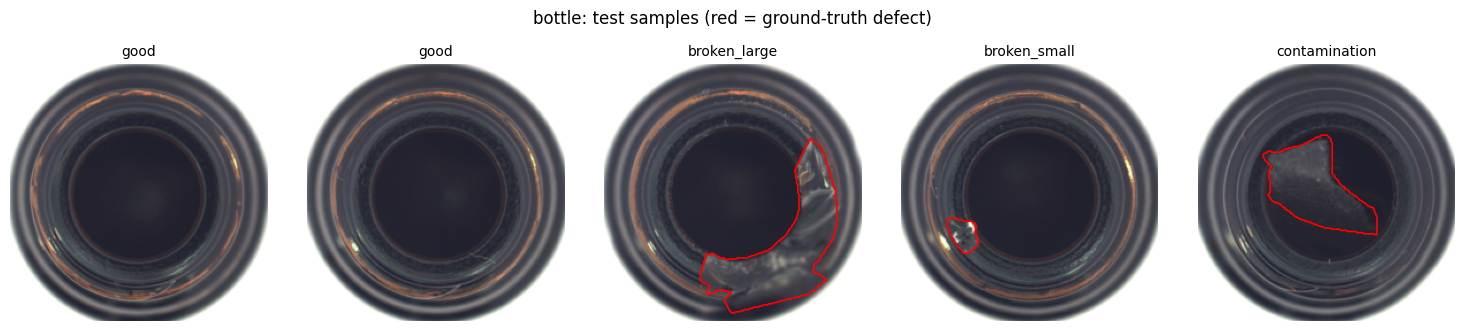

In [4]:
def show_category_samples(cat, n_defect=4):
    _, test = scan_category(cat)
    good = [r for r in test if r["label"] == 0][:2]
    by_type = {}
    for r in test:
        if r["label"] == 1:
            by_type.setdefault(r["defect"], r)
    picks = good + list(by_type.values())[:n_defect]
    fig, axes = plt.subplots(1, len(picks), figsize=(3 * len(picks), 3.2))
    for ax, r in zip(np.atleast_1d(axes), picks):
        ax.imshow(load_image(r["path"]))
        if r["mask"] is not None:
            ax.contour(load_mask(r["mask"]), levels=[0.5], colors="red", linewidths=1.2)
        ax.set_title(r["defect"], fontsize=10); ax.axis("off")
    fig.suptitle(f"{cat}: test samples (red = ground-truth defect)", y=1.02)
    plt.tight_layout(); plt.show()

show_category_samples(cfg.bench_category)

In [5]:
class Normalize(nn.Module):
    # uint8 NHWC [0,255] -> float NCHW, ImageNet-normalised. Runs inside the exported graph.
    def __init__(self):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1) * 255.0)
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1) * 255.0)

    def forward(self, x):
        # Cast first, then permute: TensorRT only allows a uint8 network input to feed a Cast directly.
        x = x.to(self.mean.dtype).permute(0, 3, 1, 2)
        return (x - self.mean) / self.std


class FeatureExtractor(nn.Module):
    # WideResNet-50-2 layer2 + layer3, 3x3 local aggregation, concatenated at layer2 resolution.
    def __init__(self, pretrained=True):
        super().__init__()
        weights = torchvision.models.Wide_ResNet50_2_Weights.IMAGENET1K_V1 if pretrained else None
        wrn = torchvision.models.wide_resnet50_2(weights=weights)
        self.norm = Normalize()
        self.stem = nn.Sequential(wrn.conv1, wrn.bn1, wrn.relu, wrn.maxpool)
        self.layer1, self.layer2, self.layer3 = wrn.layer1, wrn.layer2, wrn.layer3   # layer4/fc discarded
        self.pool = nn.AvgPool2d(kernel_size=3, stride=1, padding=1)
        self.eval().requires_grad_(False)

    def forward(self, image_u8):
        x = self.stem(self.norm(image_u8))
        f2 = self.layer2(self.layer1(x))
        f3 = self.layer3(f2)
        f2, f3 = self.pool(f2), self.pool(f3)
        f3 = F.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
        return torch.cat([f2, f3], dim=1)                      # [B, 1536, 28, 28]


class GaussianBlur2d(nn.Module):
    # Separable Gaussian blur with reflect padding (exports to Pad + 2 Conv).
    def __init__(self, sigma=4.0):
        super().__init__()
        r = int(4 * sigma + 0.5)
        k = torch.arange(-r, r + 1, dtype=torch.float32)
        g = torch.exp(-(k ** 2) / (2 * sigma ** 2)); g = g / g.sum()
        self.r = r
        self.register_buffer("kx", g.view(1, 1, 1, -1))
        self.register_buffer("ky", g.view(1, 1, -1, 1))

    def forward(self, x):
        x = F.conv2d(F.pad(x, (self.r, self.r, 0, 0), mode="reflect"), self.kx)
        return F.conv2d(F.pad(x, (0, 0, self.r, self.r), mode="reflect"), self.ky)


class PatchCore(nn.Module):
    # Exportable inference graph: uint8 image [B,H,W,3] -> (anomaly_map [B,1,H,W] fp32, score [B] fp32).
    def __init__(self, extractor, memory_bank, out_size=224, sigma=4.0, head_dtype=torch.float32):
        super().__init__()
        self.extractor, self.out_size = extractor, out_size
        bank = memory_bank.float()
        self.register_buffer("bank_t", bank.t().contiguous().to(head_dtype))        # [D, M]
        self.register_buffer("bank_sq", (bank ** 2).sum(1).to(head_dtype))         # [M]
        self.blur = GaussianBlur2d(sigma)

    def forward(self, image):
        f = self.extractor(image)                                   # [B, D, h, w], backbone dtype
        B, D, h, w = f.shape
        f = f.to(self.bank_t.dtype).flatten(2).transpose(1, 2)      # [B, h*w, D], head dtype
        d2 = (f * f).sum(-1, keepdim=True) - 2.0 * torch.matmul(f, self.bank_t) + self.bank_sq
        patch = d2.amin(dim=-1).clamp_min(0).sqrt().float()         # [B, h*w]  nearest-neighbour distance
        score = patch.amax(dim=1)                                    # [B]
        amap = patch.reshape(B, 1, h, w)
        amap = F.interpolate(amap, size=(self.out_size, self.out_size), mode="bilinear", align_corners=False)
        return self.blur(amap), score


BASE_EXTRACTOR = FeatureExtractor(cfg.pretrained).to(DEVICE)       # shared, frozen

def build_model(bank, precision="fp32"):
    # precision: 'fp32' | 'fp16' (fp16 backbone, fp32 kNN head) | 'fp16_all'
    ext = copy.deepcopy(BASE_EXTRACTOR)
    if precision in ("fp16", "fp16_all"):
        ext = ext.half()
    head = torch.float16 if precision == "fp16_all" else torch.float32
    return PatchCore(ext, bank, cfg.crop, cfg.blur_sigma, head).to(DEVICE).eval()

with torch.no_grad():
    _f = BASE_EXTRACTOR(torch.zeros(1, cfg.crop, cfg.crop, 3, dtype=torch.uint8, device=DEVICE))
EMBED_DIM, FEAT_HW = _f.shape[1], _f.shape[2:]
print(f"patch embedding dim = {EMBED_DIM}, feature grid = {tuple(FEAT_HW)}, "
      f"extractor params = {sum(p.numel() for p in BASE_EXTRACTOR.parameters()) / 1e6:.1f} M")

patch embedding dim = 1536, feature grid = (28, 28), extractor params = 24.9 M


In [6]:
@torch.no_grad()
def extract_patch_embeddings(paths):
    # Threads instead of a multi-process DataLoader: works identically on Windows and Linux
    # (Windows DataLoader workers cannot import functions defined in a notebook). PIL releases the
    # GIL while decoding, so threads keep the GPU fed; the next batch is decoded while this one runs.
    batches = [paths[i:i + cfg.batch_size] for i in range(0, len(paths), cfg.batch_size)]
    chunks = []
    with ThreadPoolExecutor(max(1, cfg.num_workers)) as pool, ThreadPoolExecutor(1) as prefetch:
        load_batch = lambda b: np.stack(list(pool.map(load_image, b)))
        nxt = prefetch.submit(load_batch, batches[0])
        for k in range(len(batches)):
            x = torch.from_numpy(nxt.result())
            if k + 1 < len(batches):
                nxt = prefetch.submit(load_batch, batches[k + 1])
            f = BASE_EXTRACTOR(x.to(DEVICE))                          # [B, D, h, w]
            chunks.append(f.flatten(2).transpose(1, 2).reshape(-1, f.shape[1]))
    return torch.cat(chunks)                                          # [N*h*w, D] fp32 on DEVICE


@torch.no_grad()
def greedy_coreset_indices(emb, n, proj_dim=128, seed=0):
    # Greedy k-centre selection (approximate minimax facility location) on a random projection.
    N, D = emb.shape
    g = torch.Generator(device=emb.device).manual_seed(seed)
    if proj_dim and proj_dim < D:
        P = torch.randn(D, proj_dim, generator=g, device=emb.device) / math.sqrt(proj_dim)
        z = emb @ P
    else:
        z = emb
    idx = torch.empty(n, dtype=torch.long, device=emb.device)
    idx[0] = torch.randint(N, (1,), generator=g, device=emb.device)
    min_d = torch.linalg.vector_norm(z - z[idx[0]], dim=1)
    for i in range(1, n):                       # no host sync inside the loop: argmax stays on the GPU
        j = torch.argmax(min_d)
        idx[i] = j
        min_d = torch.minimum(min_d, torch.linalg.vector_norm(z - z[j], dim=1))
    return idx


def split_train(paths, frac, seed):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(paths))
    k = max(1, int(round(frac * len(paths))))
    return [paths[i] for i in perm[k:]], [paths[i] for i in perm[:k]]


def fit_category(cat):
    train_paths, _ = scan_category(cat)
    fit_paths, holdout_paths = split_train(train_paths, cfg.holdout_frac, cfg.seed)
    t0 = time.perf_counter()
    emb = extract_patch_embeddings(fit_paths)
    t1 = time.perf_counter()
    n = max(1, int(round(cfg.coreset_ratio * len(emb))))
    bank = emb[greedy_coreset_indices(emb, n, cfg.proj_dim, cfg.seed)].clone()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t2 = time.perf_counter()
    info = {"n_fit_images": len(fit_paths), "n_holdout_images": len(holdout_paths),
            "n_patches": len(emb), "bank_size": n, "t_extract_s": t1 - t0, "t_coreset_s": t2 - t1}
    del emb
    return bank, holdout_paths, info

In [7]:
@torch.no_grad()
def predict_batched(fn, images, bs=16):
    # fn: torch uint8 [B,H,W,3] on DEVICE -> (anomaly_map [B,1,H,W], score [B]). Returns numpy (maps, scores).
    maps, scores = [], []
    for i in range(0, len(images), bs):
        x = torch.from_numpy(images[i:i + bs]).to(DEVICE)
        a, s = fn(x)
        maps.append(a[:, 0].float().cpu().numpy()); scores.append(s.float().cpu().numpy())
    return np.concatenate(maps), np.concatenate(scores)


def compute_aupro(maps, masks, fpr_limit=0.3, num_thresholds=200):
    # Area under the per-region-overlap curve up to `fpr_limit`, normalised to [0, 1] (Bergmann et al., IJCV 2021).
    # Thresholds are quantiles of the normal-pixel scores, so the FPR axis is sampled uniformly on [0, fpr_limit].
    neg = np.sort(maps[~masks].ravel())
    fpr_grid = np.linspace(0.0, fpr_limit, num_thresholds)
    thresholds = np.quantile(neg, 1.0 - fpr_grid)
    fpr = 1.0 - np.searchsorted(neg, thresholds, side="right") / neg.size
    structure = np.ones((3, 3), dtype=int)                      # 8-connectivity, as in the official evaluation code
    pros = []
    for m, gt in zip(maps, masks):
        if not gt.any():
            continue
        labeled, n_regions = ndimage.label(gt, structure=structure)
        for k in range(1, n_regions + 1):
            vals = np.sort(m[labeled == k])
            pros.append(1.0 - np.searchsorted(vals, thresholds, side="right") / vals.size)
    if not pros:
        return float("nan")
    pro = np.mean(pros, axis=0)
    order = np.argsort(fpr)
    return float(np.trapezoid(pro[order], fpr[order]) / fpr_limit) if hasattr(np, "trapezoid") \
        else float(np.trapz(pro[order], fpr[order]) / fpr_limit)


def evaluate(maps, scores, labels, masks):
    out = {"image_auroc": roc_auc_score(labels, scores) if len(set(labels)) == 2 else float("nan"),
           "pixel_auroc": roc_auc_score(masks.ravel(), maps.ravel()) if masks.any() else float("nan"),
           "aupro": compute_aupro(maps, masks)}
    p, r, _ = precision_recall_curve(labels, scores)
    out["image_f1_max_oracle"] = float(np.max(2 * p * r / np.clip(p + r, 1e-12, None)))
    return out


def threshold_metrics(scores, labels, thr):
    pred = scores > thr
    tp, fp = np.sum(pred & (labels == 1)), np.sum(pred & (labels == 0))
    fn, tn = np.sum(~pred & (labels == 1)), np.sum(~pred & (labels == 0))
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return {"precision@thr": prec, "recall@thr": rec, "f1@thr": 2 * prec * rec / max(prec + rec, 1e-12),
            "fpr@thr": fp / max(fp + tn, 1)}

In [8]:
all_metrics, fit_info = [], {}
for cat in cfg.categories:
    bank, holdout_paths, info = fit_category(cat)
    torch.save(bank.cpu(), cfg.out_dir / "banks" / f"{cat}.pt")
    model = build_model(bank, "fp32")

    hold_maps, hold_scores = predict_batched(model, load_images(holdout_paths), cfg.batch_size)
    thr_img, thr_pix = float(hold_scores.max()), float(hold_maps.max())

    _, test_records = scan_category(cat)
    images, masks, labels = load_test_set(test_records)
    t0 = time.perf_counter()
    maps, scores = predict_batched(model, images, cfg.batch_size)
    t_test = time.perf_counter() - t0

    m = {"category": cat, **evaluate(maps, scores, labels, masks), **threshold_metrics(scores, labels, thr_img),
         "image_threshold": thr_img, "pixel_threshold": thr_pix, **info, "t_test_s": t_test}
    all_metrics.append(m)
    fit_info[cat] = m
    print(f"{cat:<11} img AUROC {m['image_auroc']:.4f} | pix AUROC {m['pixel_auroc']:.4f} | "
          f"AUPRO {m['aupro']:.4f} | F1@thr {m['f1@thr']:.3f} | bank {info['bank_size']} "
          f"| fit {info['t_extract_s'] + info['t_coreset_s']:.1f}s")
    del model, bank
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

metrics_df = pd.DataFrame(all_metrics).set_index("category")
main_cols = ["image_auroc", "pixel_auroc", "aupro", "f1@thr", "fpr@thr", "image_f1_max_oracle"]
summary = metrics_df[main_cols].copy()
summary.loc["mean"] = summary.mean()
metrics_df.to_csv(cfg.out_dir / "results" / "metrics.csv")
(summary * 100).round(2)

bottle      img AUROC 1.0000 | pix AUROC 0.9831 | AUPRO 0.9265 | F1@thr 0.984 | bank 1474 | fit 3.5s
cable       img AUROC 0.9933 | pix AUROC 0.9835 | AUPRO 0.9238 | F1@thr 0.983 | bank 1584 | fit 3.5s
capsule     img AUROC 0.9717 | pix AUROC 0.9865 | AUPRO 0.9103 | F1@thr 0.968 | bank 1544 | fit 2.5s
carpet      img AUROC 0.9884 | pix AUROC 0.9878 | AUPRO 0.9312 | F1@thr 0.946 | bank 1976 | fit 3.8s
grid        img AUROC 0.9783 | pix AUROC 0.9646 | AUPRO 0.8662 | F1@thr 0.956 | bank 1866 | fit 3.2s
hazelnut    img AUROC 1.0000 | pix AUROC 0.9843 | AUPRO 0.9327 | F1@thr 0.993 | bank 2760 | fit 5.4s
leather     img AUROC 1.0000 | pix AUROC 0.9907 | AUPRO 0.9570 | F1@thr 0.880 | bank 1733 | fit 3.8s
metal_nut   img AUROC 0.9990 | pix AUROC 0.9844 | AUPRO 0.9184 | F1@thr 0.989 | bank 1552 | fit 1.9s
pill        img AUROC 0.9580 | pix AUROC 0.9747 | AUPRO 0.9289 | F1@thr 0.917 | bank 1882 | fit 2.6s
screw       img AUROC 0.9297 | pix AUROC 0.9789 | AUPRO 0.8963 | F1@thr 0.897 | bank 2258 |

,image_auroc,pixel_auroc,aupro,f1@thr,fpr@thr,image_f1_max_oracle
category,,,,,,
bottle,100.00,98.31,92.65,98.44,10.00,100.00
cable,99.33,98.35,92.38,98.34,0.00,98.34
capsule,97.17,98.65,91.03,96.80,17.39,97.27
carpet,98.84,98.78,93.12,94.62,32.14,97.75
grid,97.83,96.46,86.62,95.58,9.52,95.65
hazelnut,100.00,98.43,93.27,99.28,0.00,100.00
leather,100.00,99.07,95.70,88.04,78.12,100.00
metal_nut,99.90,98.44,91.84,98.92,4.55,99.47
pill,95.80,97.47,92.89,91.67,7.69,95.83


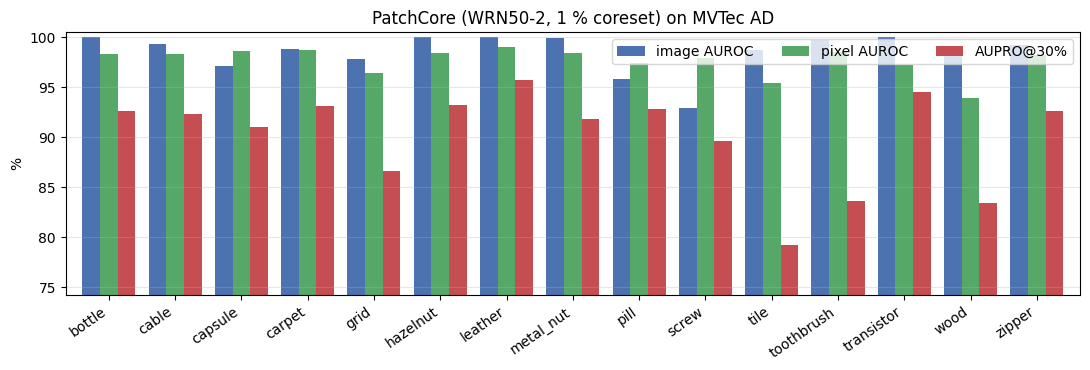

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
plot_df = (metrics_df[["image_auroc", "pixel_auroc", "aupro"]] * 100)
plot_df.plot.bar(ax=ax, width=0.8, color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_ylim(max(0, plot_df.min().min() - 5), 100.5); ax.set_ylabel("%"); ax.set_xlabel("")
ax.set_title("PatchCore (WRN50-2, 1 % coreset) on MVTec AD"); ax.legend(["image AUROC", "pixel AUROC", "AUPRO@30%"], ncol=3)
ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=35, ha="right"); plt.tight_layout()
fig.savefig(cfg.out_dir / "figures" / "metrics_per_category.png", dpi=150); plt.show()

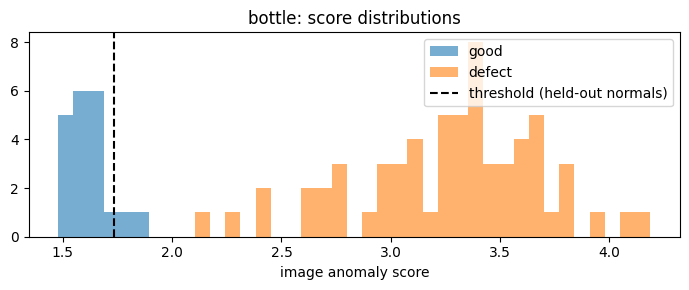

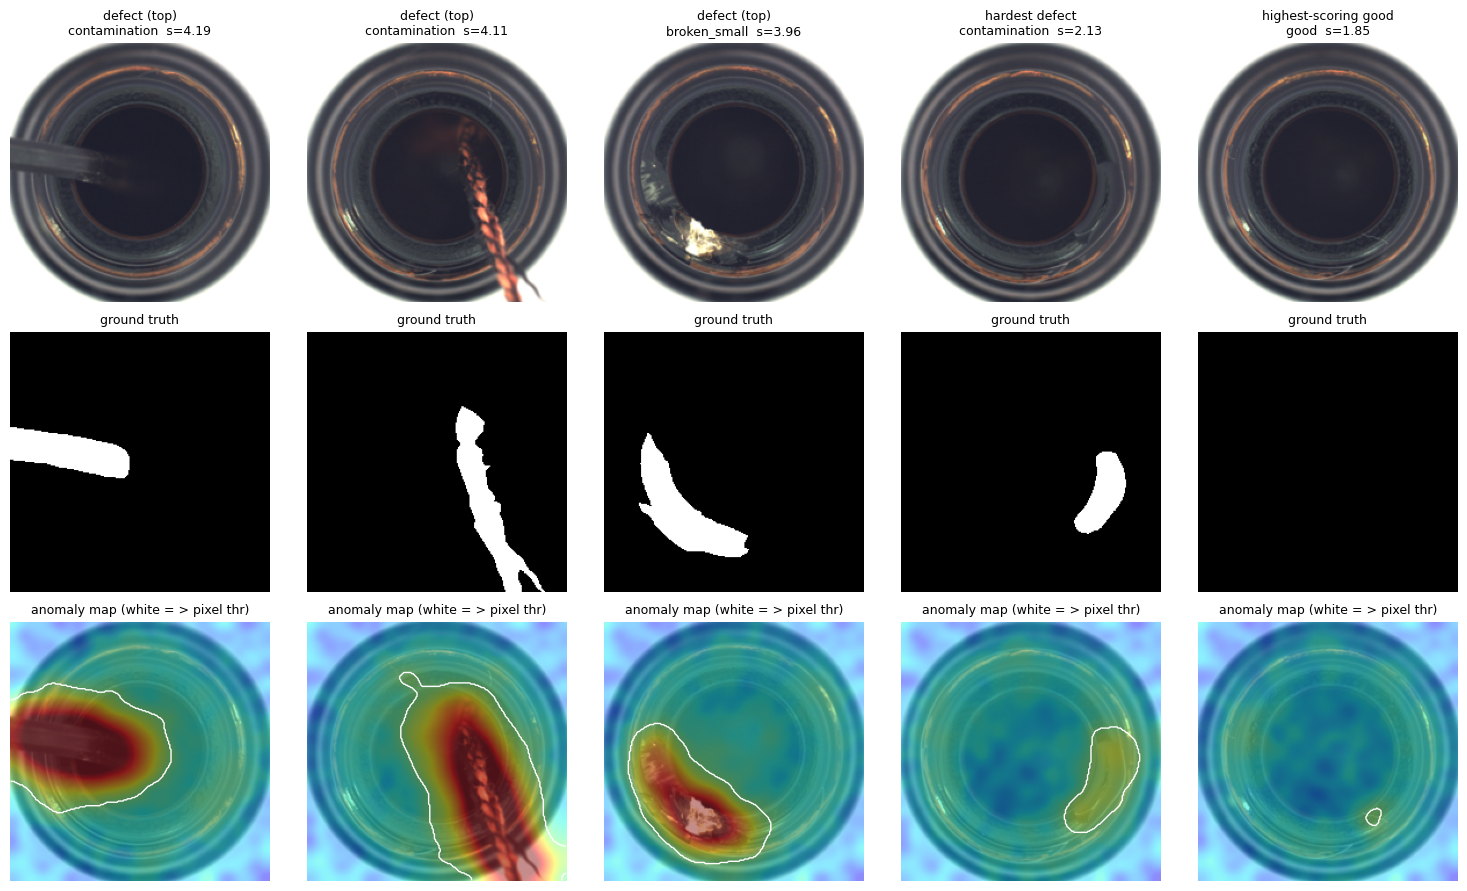

In [10]:
def jet_overlay(img, amap, vmax, alpha=0.45):
    v = np.clip(amap / vmax, 0, 1)
    return np.clip((1 - alpha) * img / 255.0 + alpha * plt.cm.jet(v)[..., :3], 0, 1)

if "fit_info" not in globals():   # Step 4 skipped in this session: reload its results from disk
    fit_info = pd.read_csv(cfg.out_dir / "results" / "metrics.csv", index_col="category").to_dict("index")
cat = cfg.bench_category
bank = torch.load(cfg.out_dir / "banks" / f"{cat}.pt").to(DEVICE)
model = build_model(bank, "fp32")
_, test_records = scan_category(cat)
images, masks, labels = load_test_set(test_records)
maps, scores = predict_batched(model, images, cfg.batch_size)
thr_img, thr_pix = fit_info[cat]["image_threshold"], fit_info[cat]["pixel_threshold"]

# Score distributions
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(scores.min(), scores.max(), 40)
ax.hist(scores[labels == 0], bins, alpha=0.6, label="good"); ax.hist(scores[labels == 1], bins, alpha=0.6, label="defect")
ax.axvline(thr_img, color="k", ls="--", label="threshold (held-out normals)")
ax.set_xlabel("image anomaly score"); ax.set_title(f"{cat}: score distributions"); ax.legend(); plt.tight_layout(); plt.show()

# Typical detections + hardest cases
defect_idx = np.where(labels == 1)[0]; good_idx = np.where(labels == 0)[0]
picks = list(defect_idx[np.argsort(-scores[defect_idx])][:3]) + [defect_idx[np.argmin(scores[defect_idx])]] \
        + [good_idx[np.argmax(scores[good_idx])]]
titles = ["defect (top)"] * 3 + ["hardest defect"] + ["highest-scoring good"]
fig, axes = plt.subplots(3, len(picks), figsize=(3 * len(picks), 9))
for j, (i, t) in enumerate(zip(picks, titles)):
    axes[0, j].imshow(images[i]); axes[0, j].set_title(f"{t}\n{test_records[i]['defect']}  s={scores[i]:.2f}", fontsize=9)
    axes[1, j].imshow(masks[i], cmap="gray"); axes[1, j].set_title("ground truth", fontsize=9)
    axes[2, j].imshow(jet_overlay(images[i], maps[i], 2 * thr_pix))
    axes[2, j].contour(maps[i] > thr_pix, levels=[0.5], colors="white", linewidths=1)
    axes[2, j].set_title("anomaly map (white = > pixel thr)", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); fig.savefig(cfg.out_dir / "figures" / f"qualitative_{cat}.png", dpi=150); plt.show()

In [11]:
def export_onnx(model, path, opset=18):
    # torch.export-based exporter (default since PyTorch 2.9); falls back to the legacy TorchScript exporter.
    dummy = torch.zeros(2, cfg.crop, cfg.crop, 3, dtype=torch.uint8, device=DEVICE)   # batch 2: avoid specialising on 1
    names = dict(input_names=["image"], output_names=["anomaly_map", "score"], opset_version=opset)
    with torch.no_grad():
        try:
            from torch.export import Dim
            torch.onnx.export(model, (dummy,), str(path), dynamo=True, external_data=False, verbose=False,
                              dynamic_shapes={"image": {0: Dim("batch", min=1, max=64)}}, **names)
        except Exception as e:
            print(f"  dynamo exporter failed ({type(e).__name__}: {e}); using the TorchScript exporter")
            torch.onnx.export(model, (dummy,), str(path), dynamo=False, **names,
                              dynamic_axes={"image": {0: "batch"}, "anomaly_map": {0: "batch"}, "score": {0: "batch"}})
    onnx.checker.check_model(str(path))
    return path

def ort_session(path, providers):
    so = ort.SessionOptions(); so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(str(path), so, providers=providers)

def write_meta(cat, model_dir):
    m = fit_info[cat]
    meta = {"category": cat, "method": "PatchCore", "backbone": "wide_resnet50_2 (layer2+layer3)",
            "coreset_ratio": cfg.coreset_ratio, "bank_size": int(m["bank_size"]),
            "preprocess": {"resize": cfg.resize, "crop": cfg.crop, "color": "RGB", "layout": "NHWC", "dtype": "uint8"},
            "io": {"input": "image", "outputs": ["anomaly_map", "score"]},
            "thresholds": {"image": m["image_threshold"], "pixel": m["pixel_threshold"],
                           "rule": "max over held-out normal training images"},
            "metrics": {k: float(m[k]) for k in ["image_auroc", "pixel_auroc", "aupro", "f1@thr", "fpr@thr"]},
            "exported_with": {"torch": torch.__version__, "opset": 18}, "created": time.strftime("%Y-%m-%d %H:%M:%S")}
    (model_dir / "meta.json").write_text(json.dumps(meta, indent=2))

if "fit_info" not in globals():   # Step 4 skipped in this session: reload its results from disk
    fit_info = pd.read_csv(cfg.out_dir / "results" / "metrics.csv", index_col="category").to_dict("index")
if onnx is None:
    print("onnx not installed: skipping export")
else:
    parity = []
    for cat in tqdm(cfg.categories, desc="export"):
        model_dir = cfg.out_dir / "models" / cat
        model_dir.mkdir(parents=True, exist_ok=True)
        bank = torch.load(cfg.out_dir / "banks" / f"{cat}.pt").to(DEVICE)
        precisions = ["fp32", "fp16"] + (["fp16_all"] if cat == cfg.bench_category else [])
        _, test_records = scan_category(cat)
        sample = load_images([r["path"] for r in test_records[:: max(1, len(test_records) // 8)]][:8])
        ref_maps, ref_scores = predict_batched(build_model(bank, "fp32"), sample)
        for prec in precisions:
            path = export_onnx(build_model(bank, prec), model_dir / f"model_{prec}.onnx")
            if ort is not None:
                prov = ["CUDAExecutionProvider", "CPUExecutionProvider"] if HAS_ORT_CUDA else ["CPUExecutionProvider"]
                try:
                    o_maps, o_scores = ort_session(path, prov).run(None, {"image": sample})
                except Exception as e:   # ORT's CPU EP lacks some fp16 kernels; on the GPU this does not happen
                    print(f"  {cat}/{prec}: ORT parity check skipped ({type(e).__name__})")
                    continue
                parity.append({"category": cat, "precision": prec, "size_MB": path.stat().st_size / 2**20,
                               "max_abs_dscore": float(np.abs(o_scores - ref_scores).max()),
                               "max_rel_dscore": float(np.abs(o_scores - ref_scores).max() / np.abs(ref_scores).max()),
                               "max_abs_dmap": float(np.abs(o_maps[:, 0] - ref_maps).max())})
        write_meta(cat, model_dir)
        del bank
    parity_df = pd.DataFrame(parity)
    display(parity_df.groupby("precision")[["size_MB", "max_rel_dscore", "max_abs_dmap"]].max())

export:   0%|          | 0/15 [00:00<?, ?it/s]

W1028 13:05:40.397000 8884 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


,size_MB,max_rel_dscore,max_abs_dmap
precision,,,
fp16,63.808458,0.000698,0.019881
fp16_all,51.950755,0.000692,0.020207
fp32,111.191628,0.000003,0.000018


In [12]:
TRT_TO_TORCH = {}
if HAS_TRT:
    TRT_TO_TORCH = {trt.DataType.FLOAT: torch.float32, trt.DataType.HALF: torch.float16,
                    trt.DataType.UINT8: torch.uint8, trt.DataType.INT32: torch.int32, trt.DataType.BOOL: torch.bool}
    if hasattr(trt.DataType, "INT64"):
        TRT_TO_TORCH[trt.DataType.INT64] = torch.int64


class TRTModel:
    # Minimal TensorRT runner using PyTorch tensors as device buffers (no pycuda/cuda-python needed).
    def __init__(self, engine_path):
        self.engine = trt.Runtime(trt.Logger(trt.Logger.WARNING)).deserialize_cuda_engine(Path(engine_path).read_bytes())
        self.ctx = self.engine.create_execution_context()
        names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
        self.inp = next(n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT)
        self.outs = [n for n in names if n != self.inp]
        self._cache = {}

    def _buffers(self, shape):
        if shape not in self._cache:
            self.ctx.set_input_shape(self.inp, shape)
            self._cache[shape] = {n: torch.empty(tuple(self.ctx.get_tensor_shape(n)),
                                                 dtype=TRT_TO_TORCH[self.engine.get_tensor_dtype(n)], device=DEVICE)
                                  for n in self.outs}
        return self._cache[shape]

    def __call__(self, x):
        x = x.contiguous()
        outs = self._buffers(tuple(x.shape))
        self.ctx.set_input_shape(self.inp, tuple(x.shape))
        self.ctx.set_tensor_address(self.inp, x.data_ptr())
        for n, t in outs.items():
            self.ctx.set_tensor_address(n, t.data_ptr())
        if not self.ctx.execute_async_v3(torch.cuda.current_stream().cuda_stream):
            raise RuntimeError("TensorRT execution failed")
        return outs["anomaly_map"], outs["score"]


import subprocess

BUILD_SCRIPT = PROJECT_ROOT / "tools" / "build_trt_engine.py"
ENGINES = {}
if HAS_TRT:
    assert BUILD_SCRIPT.exists(), f"Missing {BUILD_SCRIPT} - copy the tools/ folder from the project zip."
    bench_dir = cfg.out_dir / "models" / cfg.bench_category
    for prec in ("fp32", "fp16", "fp16_all"):
        onnx_path = bench_dir / f"model_{prec}.onnx"
        engine_path = cfg.out_dir / "engines" / f"{cfg.bench_category}_{prec}_trt{trt.__version__}.engine"
        if not engine_path.exists():
            # Separate process: no PyTorch/ORT CUDA DLLs next to TensorRT's, and a crash can't kill the kernel.
            # CUDA_VISIBLE_DEVICES is inherited, so it builds on the same GPU as the notebook.
            cmd = [sys.executable, str(BUILD_SCRIPT), "--onnx", str(onnx_path), "--engine", str(engine_path),
                   "--max-batch", str(max(cfg.bench_batches))]
            r = subprocess.run(cmd, capture_output=True, text=True, env=os.environ.copy())
            print(r.stdout.strip())
            if r.returncode != 0:
                print(r.stderr[-6000:])
                code = r.returncode & 0xFFFFFFFF
                hint = " (0xC0000005 = access violation: native crash inside TensorRT/CUDA)" if code == 0xC0000005 else ""
                raise RuntimeError(f"engine build failed for {prec}: exit code {r.returncode} ({code:#x}){hint}. "
                                   f"Re-run with --verbose from a terminal:\n  {' '.join(cmd)} --verbose")
        ENGINES[prec] = engine_path
else:
    print("TensorRT/GPU not available: skipping engine build")

In [13]:
class ORTModel:
    # ONNX Runtime CUDA EP with I/O binding on PyTorch-owned device buffers.
    def __init__(self, path):
        self.sess = ort_session(path, ["CUDAExecutionProvider"])
        self._cache = {}

    def __call__(self, x):
        x = x.contiguous()
        B = x.shape[0]
        if B not in self._cache:
            self._cache[B] = (torch.empty(B, 1, cfg.crop, cfg.crop, device=DEVICE), torch.empty(B, device=DEVICE))
        amap, score = self._cache[B]
        io = self.sess.io_binding()
        io.bind_input("image", "cuda", 0, np.uint8, tuple(x.shape), x.data_ptr())
        io.bind_output("anomaly_map", "cuda", 0, np.float32, tuple(amap.shape), amap.data_ptr())
        io.bind_output("score", "cuda", 0, np.float32, tuple(score.shape), score.data_ptr())
        torch.cuda.current_stream().synchronize()   # ORT uses its own stream: make sure x is ready
        self.sess.run_with_iobinding(io)
        return amap, score


def time_backend(fn, x, warmup, iters):
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    with torch.no_grad():
        for _ in range(warmup):
            fn(x)
        sync()
        t = np.empty(iters)
        for i in range(iters):
            t0 = time.perf_counter(); fn(x); sync(); t[i] = time.perf_counter() - t0
    t *= 1e3
    return {"mean_ms": t.mean(), "p50_ms": np.percentile(t, 50), "p95_ms": np.percentile(t, 95), "std_ms": t.std(),
            "throughput_img_s": x.shape[0] / (t.mean() / 1e3)}


cat = cfg.bench_category
bank = torch.load(cfg.out_dir / "banks" / f"{cat}.pt").to(DEVICE)
model_dir = cfg.out_dir / "models" / cat
backends = {"PyTorch fp32": build_model(bank, "fp32")}
if DEVICE.type == "cuda":
    backends["PyTorch fp16"] = build_model(bank, "fp16")
if HAS_ORT_CUDA:
    backends["ORT-CUDA fp32"] = ORTModel(model_dir / "model_fp32.onnx")
    backends["ORT-CUDA fp16"] = ORTModel(model_dir / "model_fp16.onnx")
for prec, path in ENGINES.items():
    backends[f"TensorRT {prec}"] = TRTModel(path)

_, test_records = scan_category(cat)
images, masks, labels = load_test_set(test_records)
ref_maps, ref_scores = predict_batched(backends["PyTorch fp32"], images, max(cfg.bench_batches))

rows = []
for name, fn in backends.items():
    maps_b, scores_b = predict_batched(fn, images, max(cfg.bench_batches))
    acc = {"image_auroc": roc_auc_score(labels, scores_b), "pixel_auroc": roc_auc_score(masks.ravel(), maps_b.ravel()),
           "max_rel_dscore": float(np.abs(scores_b - ref_scores).max() / np.abs(ref_scores).max())}
    for B in cfg.bench_batches:
        x = torch.from_numpy(np.ascontiguousarray(images[np.arange(B) % len(images)])).to(DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        r = time_backend(fn, x, cfg.bench_warmup, cfg.bench_iters)
        rows.append({"backend": name, "batch": B, **r, **acc})
        print(f"{name:<18} B={B}: p50 {r['p50_ms']:7.2f} ms | p95 {r['p95_ms']:7.2f} ms | {r['throughput_img_s']:7.1f} img/s")

bench_df = pd.DataFrame(rows)
bench_df.to_csv(cfg.out_dir / "results" / "benchmark.csv", index=False)
env = {"gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu", "torch": torch.__version__,
       "cuda": torch.version.cuda, "onnxruntime": getattr(ort, "__version__", None),
       "tensorrt": getattr(trt, "__version__", None), "category": cat, "bank_size": int(bank.shape[0]),
       "warmup": cfg.bench_warmup, "iters": cfg.bench_iters}
(cfg.out_dir / "results" / "benchmark_env.json").write_text(json.dumps(env, indent=2))
pd.set_option("display.precision", 4)
bench_table = bench_df.pivot_table(index="backend", columns="batch", values=["p50_ms", "p95_ms", "throughput_img_s"],
                                   sort=False)
bench_table.columns = [f"{v} (B={b})" for v, b in bench_table.columns]
bench_table.join(bench_df.groupby("backend", sort=False)[["image_auroc", "pixel_auroc", "max_rel_dscore"]].first())

PyTorch fp32       B=1: p50    6.92 ms | p95    9.34 ms |   138.6 img/s
PyTorch fp32       B=8: p50   21.51 ms | p95   22.82 ms |   369.7 img/s
PyTorch fp16       B=1: p50    7.51 ms | p95    9.95 ms |   127.3 img/s
PyTorch fp16       B=8: p50   10.36 ms | p95   13.37 ms |   743.8 img/s
ORT-CUDA fp32      B=1: p50    4.09 ms | p95    4.78 ms |   238.7 img/s
ORT-CUDA fp32      B=8: p50   25.97 ms | p95   29.14 ms |   306.1 img/s
ORT-CUDA fp16      B=1: p50    3.44 ms | p95    4.68 ms |   284.1 img/s
ORT-CUDA fp16      B=8: p50   14.58 ms | p95   17.72 ms |   534.8 img/s
TensorRT fp32      B=1: p50    3.08 ms | p95    5.63 ms |   276.4 img/s
TensorRT fp32      B=8: p50   24.49 ms | p95   27.93 ms |   325.8 img/s
TensorRT fp16      B=1: p50    1.44 ms | p95    2.39 ms |   652.5 img/s
TensorRT fp16      B=8: p50   11.03 ms | p95   14.46 ms |   714.6 img/s
TensorRT fp16_all  B=1: p50    1.14 ms | p95    1.79 ms |   839.7 img/s
TensorRT fp16_all  B=8: p50    7.48 ms | p95   10.19 ms |  1051.

,p50_ms (B=1),p50_ms (B=8),p95_ms (B=1),p95_ms (B=8),throughput_img_s (B=1),throughput_img_s (B=8),image_auroc,pixel_auroc,max_rel_dscore
backend,,,,,,,,,
PyTorch fp32,6.9181,21.5123,9.3418,22.8167,138.5723,369.6983,1.0,0.9831,0.0000e+00
PyTorch fp16,7.5149,10.3550,9.9523,13.3701,127.3039,743.7834,1.0,0.9831,8.7372e-04
ORT-CUDA fp32,4.0851,25.9726,4.7776,29.1382,238.6619,306.0992,1.0,0.9831,1.0533e-06
ORT-CUDA fp16,3.4382,14.5823,4.6801,17.7209,284.0935,534.8085,1.0,0.9831,1.0005e-03
TensorRT fp32,3.0840,24.4859,5.6288,27.9325,276.3707,325.7809,1.0,0.9831,5.4090e-06
TensorRT fp16,1.4373,11.0280,2.3899,14.4641,652.4721,714.5676,1.0,0.9831,7.6295e-04
TensorRT fp16_all,1.1404,7.4768,1.7917,10.1934,839.6973,1051.4146,1.0,0.9831,1.5197e-02


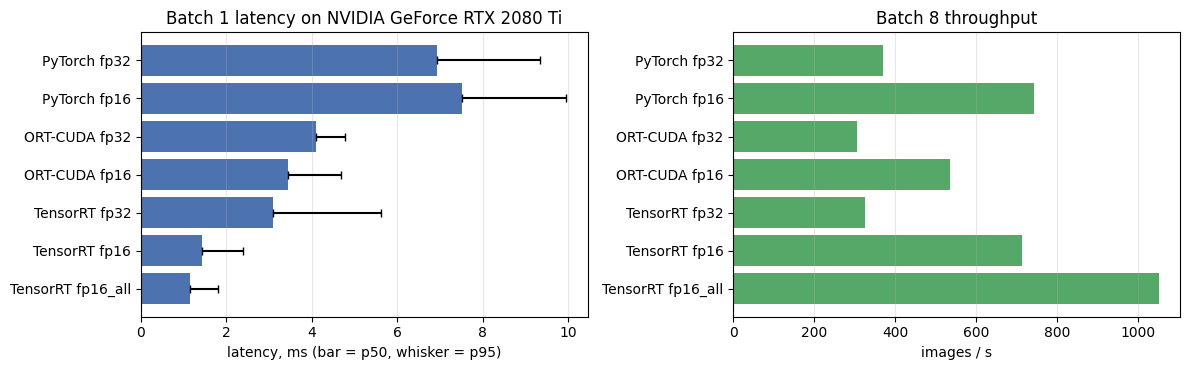

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
b1 = bench_df[bench_df.batch == min(cfg.bench_batches)]
axes[0].barh(b1.backend, b1.p50_ms, xerr=[b1.p50_ms * 0, b1.p95_ms - b1.p50_ms], color="#4C72B0", capsize=3)
axes[0].invert_yaxis(); axes[0].set_xlabel("latency, ms (bar = p50, whisker = p95)")
axes[0].set_title(f"Batch {min(cfg.bench_batches)} latency on {env['gpu']}")
bN = bench_df[bench_df.batch == max(cfg.bench_batches)]
axes[1].barh(bN.backend, bN.throughput_img_s, color="#55A868"); axes[1].invert_yaxis()
axes[1].set_xlabel("images / s"); axes[1].set_title(f"Batch {max(cfg.bench_batches)} throughput")
for ax in axes: ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); fig.savefig(cfg.out_dir / "figures" / "benchmark.png", dpi=150); plt.show()

In [15]:
best_name = bench_df[bench_df.batch == 1].sort_values("p50_ms").iloc[0]["backend"]
fn = backends[best_name]
paths = [r["path"] for r in test_records][:100]
sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
stages = {"decode+preprocess (CPU)": [], "H2D copy": [], "inference": [], "D2H copy": [], "total": []}
with torch.no_grad():
    for k, p in enumerate(paths * 2):                   # first pass = warm-up (file cache, allocator)
        t0 = time.perf_counter(); img = load_image(p)
        t1 = time.perf_counter(); x = torch.from_numpy(img[None]).to(DEVICE); sync()
        t2 = time.perf_counter(); a, s = fn(x); sync()
        t3 = time.perf_counter(); a_np, s_np = a.cpu().numpy(), s.cpu().numpy()
        t4 = time.perf_counter()
        if k >= len(paths):
            for key, v in zip(stages, (t1 - t0, t2 - t1, t3 - t2, t4 - t3, t4 - t0)):
                stages[key].append(v * 1e3)
e2e = pd.DataFrame({k: {"p50_ms": np.percentile(v, 50), "p95_ms": np.percentile(v, 95)} for k, v in stages.items()}).T
print(f"backend: {best_name}")
e2e.round(3)

backend: TensorRT fp16_all


,p50_ms,p95_ms
decode+preprocess (CPU),19.626,20.545
H2D copy,0.269,0.316
inference,3.785,4.195
D2H copy,0.251,0.313
total,23.843,25.034


In [16]:
import requests

API_URL = os.environ.get("API_URL", "http://127.0.0.1:8000")
try:
    health = requests.get(f"{API_URL}/health", timeout=3).json()
    API_UP = True
    print(json.dumps(health, indent=2))
except requests.RequestException as e:
    API_UP = False
    print(f"API not reachable at {API_URL} ({type(e).__name__}). Start the container, then re-run.")

{
  "status": "ok",
  "backend": "trt",
  "precision": "fp16",
  "categories": [
    "bottle"
  ],
  "runtime": "tensorrt-11.4.0.106"
}


,file,label,api_score,notebook_fp32_score,rel_diff,is_anomalous,api_preprocess_ms,api_inference_ms,api_total_ms
0,broken_large/000.png,1,3.3827,3.3825,5.6882e-05,True,19.701,6.101,32.998
1,broken_large/001.png,1,3.3887,3.3885,7.6343e-05,True,19.659,5.923,32.532
2,broken_large/002.png,1,3.4006,3.4014,2.3208e-04,True,18.899,6.854,32.734
3,good/000.png,0,1.5444,1.5440,2.7200e-04,False,19.042,6.653,32.803
4,good/001.png,0,1.8506,1.8505,5.6818e-05,True,19.546,6.785,33.557


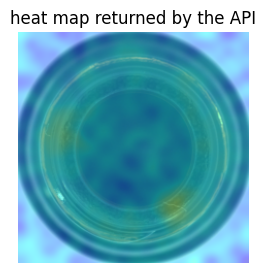

rel_diff ~1e-3 is expected when the server runs the fp16 engine; ~1e-5 for fp32.


In [17]:
if API_UP and cfg.bench_category in health["categories"]:
    import base64, io
    cat = cfg.bench_category
    _, test_records = scan_category(cat)
    picks = [r for r in test_records if r["label"] == 1][:3] + [r for r in test_records if r["label"] == 0][:2]
    ref_model = build_model(torch.load(cfg.out_dir / "banks" / f"{cat}.pt").to(DEVICE), "fp32")
    rows = []
    for r in picks:
        with open(r["path"], "rb") as f:
            resp = requests.post(f"{API_URL}/predict/{cat}", files={"file": (r["path"].name, f, "image/png")},
                                 params={"return_heatmap": "true"}, timeout=30).json()
        _, ref_s = predict_batched(ref_model, load_image(r["path"])[None])
        rows.append({"file": f"{r['defect']}/{r['path'].name}", "label": r["label"], "api_score": resp["score"],
                     "notebook_fp32_score": float(ref_s[0]), "rel_diff": abs(resp["score"] - ref_s[0]) / ref_s[0],
                     "is_anomalous": resp["is_anomalous"], **{f"api_{k}": v for k, v in resp["timing_ms"].items()}})
    display(pd.DataFrame(rows))
    heat = Image.open(io.BytesIO(base64.b64decode(resp["heatmap_png_base64"])))
    plt.figure(figsize=(3, 3)); plt.imshow(heat); plt.axis("off"); plt.title("heat map returned by the API"); plt.show()
    print("rel_diff ~1e-3 is expected when the server runs the fp16 engine; ~1e-5 for fp32.")
else:
    print("skipped")

In [18]:
def load_test(url, files, concurrency, n_requests):
    payloads = [(p.name, p.read_bytes()) for p in files]
    def one(i):
        name, data = payloads[i % len(payloads)]
        t0 = time.perf_counter()
        r = requests.post(url, files={"file": (name, data, "image/png")}, timeout=60)
        r.raise_for_status()
        return (time.perf_counter() - t0) * 1e3
    one(0)                                                        # warm-up
    t0 = time.perf_counter()
    with ThreadPoolExecutor(concurrency) as ex:
        lat = np.array(list(ex.map(one, range(n_requests))))
    wall = time.perf_counter() - t0
    return {"concurrency": concurrency, "req_per_s": n_requests / wall,
            "p50_ms": np.percentile(lat, 50), "p95_ms": np.percentile(lat, 95)}

if API_UP and cfg.bench_category in health["categories"]:
    files = [r["path"] for r in scan_category(cfg.bench_category)[1]][:20]
    lt = pd.DataFrame([load_test(f"{API_URL}/predict/{cfg.bench_category}", files, c, 40 if os.environ.get("QUICK_RUN") else 200)
                       for c in (1, 4, 8)])
    lt.to_csv(cfg.out_dir / "results" / "api_load_test.csv", index=False)
    display(lt.round(2))
else:
    print("skipped")

,concurrency,req_per_s,p50_ms,p95_ms
0,1,22.31,46.64,56.83
1,4,95.96,38.90,64.22
2,8,144.13,53.61,64.63
